# What are recommendations worth? Rebuilding Netflix's choice-model study on MovieLens

Netflix's post [Measuring the Impact of Personalized Recommendations](https://netflixtechblog.com/measuring-the-impact-of-personalized-recommendations-4c26be3a4d96) (Zielnicki, Aridor, Bibaut, Tran, Chou, Kallus; paper: [arXiv 2511.07280](https://arxiv.org/abs/2511.07280)) asks a hard question: **how much viewing do recommendations actually cause?**

You can't just turn recommendations off for millions of members. And you can't compare "watched when recommended" vs "not recommended": the recommender targets people who were likely to watch anyway. Their answer:

1. A **daily choice model**: each member picks one title or "nothing today". Utility = low-rank taste `A_i·B_j` + a **recommendation bonus** `β_j` when title j is shown.
2. **Identification**: the recommender explores at random. Once you condition on everything the recommender knew, *which* titles got shown is as good as random. (An assumption — they say so.)
3. **Validation**: a small A/B test that nudges recommendations away from some titles. Does the model predict where the lost viewing goes (the *diversion ratios*)? Theirs: correlation 0.86.
4. **Counterfactuals**: swap the recommender for random / popularity / matrix factorization → −16% / −12% / −4% engagement.
5. **Decomposition**: of the extra viewing a recommended title gets, how much is *selection* (people who'd watch anyway), *exposure* (just being shown), *targeting* (shown to the right people)?

This notebook rebuilds all five on MovieLens, then adds two things the post doesn't have:
- **Uncertainty bands** on the counterfactuals (the post reports none).
- **A stress test**: what happens to the numbers when the identification assumption is false?

**Real:** ~890k MovieLens ratings → taste vectors, popularity, genres, and each member's pre-period history.
**Simulated:** 40 days of recommendations and viewing. That's the point: in a simulation we *know* the true answer, so we can check whether the method recovers it.

Credit: the method belongs to the Netflix authors. This is an independent educational rebuild.

In [1]:
# all imports in one cell
import os, urllib.request, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import svds
import torch
import torch.nn as nn

SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
os.makedirs("figures", exist_ok=True)

## 1. Data → tastes, popularity, history

Same plain operation as before: truncated SVD of the "liked" matrix (rating ≥ 4). Top 300 titles. We sample 4,000 members with at least 3 liked titles. Each member's liked titles are their **history**: viewing that happened before our 40 simulated days. The choice model will only see this history, never the true taste vectors.

In [2]:
PARQUET_URL = ("https://huggingface.co/datasets/ashraq/movielens_ratings/"
               "resolve/main/data/train-00000-of-00001-8c8c7645a52d95e5.parquet")
if not os.path.exists("ratings.parquet"):
    urllib.request.urlretrieve(PARQUET_URL, "ratings.parquet")

df = pd.read_parquet("ratings.parquet").rename(columns={"movie_id": "movieId", "user_id": "userId"})
top = df.groupby("movieId").size().sort_values(ascending=False).index[:300]
d = df[df.movieId.isin(top)]
uc = d.groupby("userId").size()
d = d[d.userId.isin(uc[uc >= 10].index)]
uidx = {u: i for i, u in enumerate(d.userId.unique())}
tidx = {t: i for i, t in enumerate(top)}
liked = (d.rating >= 4).astype(float).values
M = csr_matrix((liked, (d.userId.map(uidx).values, d.movieId.map(tidx).values)), shape=(len(uidx), 300))

u_, s_, vt_ = svds(M, k=16)
U = u_ * np.sqrt(s_); V = vt_.T * np.sqrt(s_)
U -= U.mean(0); V -= V.mean(0)
Un = U / (np.linalg.norm(U, axis=1, keepdims=True) + 1e-9)
Vn = V / (np.linalg.norm(V, axis=1, keepdims=True) + 1e-9)
counts = d.groupby("movieId").size().reindex(top).values
pop = (np.log(counts) - np.log(counts).mean()) / np.log(counts).std()
meta = df.drop_duplicates("movieId").set_index("movieId").reindex(top)
genres = meta.genres.str.split("|")

H_all = M.toarray() > 0
members = rng.choice(np.where(H_all.sum(1) >= 3)[0], 4000, replace=False)
HIST = H_all[members]                      # (I, J) pre-period history
TASTE = Un[members] @ Vn.T                 # (I, J) true affinity — hidden from the model
I, J = HIST.shape
print(f"{I} members, {J} titles, avg history {HIST.sum(1).mean():.1f} titles")

4000 members, 300 titles, avg history 16.3 titles


## 2. The simulated world (every assumption numbered)

- **Assumption 1 — true utility.** `v_ij = 3.0·affinity_ij − 7.0 + 0.6·popularity_j`. Calibrated so ~28% of members watch something on a given day.
- **Assumption 2 — recommendation bonus.** If title j is in member i's 10 recommendations today, add `β_j ~ Normal(1.1, 0.3)`. A bonus of 1.1 roughly triples the odds of watching (e^1.1 ≈ 3), in line with the paper's "exposure roughly triples consumption".
- **Assumption 3 — choice.** Each day each member picks one title or "nothing" (utility 0), with the standard logit (Gumbel) noise. Exactly the paper's Eq. 1, with one canvas.
- **Assumption 4 — no rewatching.** Titles in the history, or watched during the 40 days, can't be picked or recommended.
- **Assumption 5 — the current recommender.** It scores titles with its own estimate of utility (truth + persistent noise, sd 0.5) and samples 10 titles each day, favoring high scores (temperature 0.7). The sampling is the **exploration**. Because the recommender's noise is unrelated to viewing, "which titles got shown, given true taste" is random. So the paper's identification assumption holds **by construction** here. Section 7 breaks it on purpose.

In [3]:
N_SLOTS, T_DAYS = 10, 40
A_TRUE, C0, C1 = 3.0, -7.0, 0.6
BETA_TRUE = rng.normal(1.1, 0.3, J)                        # Assumption 2
V_TRUE = A_TRUE * TASTE + C0 + C1 * pop                     # Assumption 1
REC_NOISE = rng.normal(0, 0.5, (I, J))                      # Assumption 5

def gumbel_topk(score, watched, rng, temp=0.7, k=N_SLOTS):
    # sample k titles without replacement, favoring high scores (exploration)
    g = score / temp + rng.gumbel(size=score.shape)
    g[watched] = -np.inf
    return np.argpartition(-g, k, axis=1)[:, :k]

def choice_probs(util_base, beta, rec, watched):
    # Eq. 1: logit over unwatched titles + "nothing" (utility 0). Returns (I, J) title probs and (I,) P(nothing)
    Cm = np.zeros(util_base.shape, bool); np.put_along_axis(Cm, rec, True, axis=1)
    u = util_base + beta * Cm
    u = np.where(watched, -np.inf, u)
    mx = np.maximum(u.max(1, keepdims=True), 0.0)
    e = np.exp(u - mx); e0 = np.exp(-mx[:, 0])
    Z = e.sum(1) + e0
    return e / Z[:, None], e0 / Z

def simulate(v_true, rec_score, rng, days=T_DAYS):
    watched = HIST.copy()
    recs = np.zeros((I, days, N_SLOTS), int); choice = np.full((I, days), J)   # J = "nothing"
    watch_day = np.full((I, J), 10_000)
    for t in range(days):
        rec = gumbel_topk(rec_score, watched, rng)
        p, p0 = choice_probs(v_true, BETA_TRUE, rec, watched)
        cum = np.hstack([p, p0[:, None]]).cumsum(1)
        ch = (rng.random((I, 1)) < cum).argmax(1)
        recs[:, t] = rec; choice[:, t] = ch
        w = np.where(ch < J)[0]
        watched[w, ch[w]] = True; watch_day[w, ch[w]] = t
    return recs, choice, watch_day, watched

t0 = time.time()
RECS, CHOICE, WATCH_DAY, WATCHED_END = simulate(V_TRUE, V_TRUE + REC_NOISE, rng)
print(f"simulated {I*T_DAYS:,} member-days in {time.time()-t0:.1f}s")
print(f"daily engagement {(CHOICE < J).mean():.3f} | titles watched per member {(CHOICE < J).sum(1).mean():.1f}")

simulated 160,000 member-days in 2.2s
daily engagement 0.284 | titles watched per member 11.4


## 3. The naive estimate (and why it's wrong)

Plain operation: across every member-day and every unwatched title, compare the watch rate when the title was recommended vs when it wasn't. This is what a dashboard would show.

In [4]:
rec_mask = np.zeros((I, T_DAYS, J), bool)
np.put_along_axis(rec_mask, RECS, True, axis=2)
avail = np.ones((I, T_DAYS, J), bool)
for t in range(T_DAYS):
    avail[:, t] = ~(HIST | (WATCH_DAY < t))
watched_now = np.zeros((I, T_DAYS, J), bool)
ii, tt = np.nonzero(CHOICE < J)
watched_now[ii, tt, CHOICE[ii, tt]] = True

rate_rec = watched_now[avail & rec_mask].mean()
rate_not = watched_now[avail & ~rec_mask].mean()
naive_ratio = rate_rec / rate_not
true_ratio = np.exp(BETA_TRUE).mean()
print(f"watch rate when recommended {rate_rec:.4f} vs not {rate_not:.5f}")
print(f"naive 'recommendations multiply viewing by' {naive_ratio:.1f}x | true causal multiplier ~{true_ratio:.1f}x")

watch rate when recommended 0.0062 vs not 0.00083
naive 'recommendations multiply viewing by' 7.5x | true causal multiplier ~3.1x


The naive ratio mixes two things: recommendations *cause* viewing, and the recommender *picks* titles people already like. Separating them needs a model.

## 4. The choice model (the paper's Eq. 1, simplified)

Plain description:
- **Member vector** `A_i`: the average of learned title embeddings over the member's history, through one linear layer, then normalized to a learned length. (The paper uses an attention model over the viewing sequence; we use mean-pooling. Same idea: the member is summarized from what they watched.)
- **Utility** `u_ijt = A_i·B_j + δ_j + β_j·[j recommended to i on day t]`, "nothing" = 0.
- **Fit**: maximum likelihood (cross-entropy over the 301 options), Adam, PyTorch. The `β_j` are pulled toward a common mean (small L2 penalty) so rarely-shown titles don't get wild values.

It never sees the true tastes, the recommender's scores, or the noise.

In [5]:
class ChoiceModel(nn.Module):
    def __init__(self, J, d=16):
        super().__init__()
        self.E = nn.Parameter(torch.randn(J, d) * 0.1)      # embeddings used to summarize history
        self.W = nn.Linear(d, d)
        self.B = nn.Parameter(torch.randn(J, d) * 0.1)      # title embeddings
        self.delta = nn.Parameter(torch.full((J,), -5.0))   # title intercepts
        self.beta0 = nn.Parameter(torch.tensor(0.5))        # common rec bonus
        self.beta_dev = nn.Parameter(torch.zeros(J))        # title-specific deviation
        self.scale = nn.Parameter(torch.tensor(3.0))        # strength of taste
    def member_vec(self, hist):                             # hist: (b, J) 0/1
        h = hist / hist.sum(1, keepdim=True).clamp(min=1)   # mean-pool the history embeddings
        a = self.W(h @ self.E)
        return self.scale * a / a.norm(dim=1, keepdim=True).clamp(min=1e-6)   # normalize, learn one scale
    def base_util(self, hist):
        return self.member_vec(hist) @ self.B.T + self.delta
    @property
    def beta(self):
        return self.beta0 + self.beta_dev

def fit_choice_model(recs, choice, watch_day, members_idx=None, epochs=30, bs=4096, lr=0.01, l2=1.0, seed=0):
    torch.manual_seed(seed)
    if members_idx is None: members_idx = np.arange(I)
    # one row per (member, day)
    mi = np.repeat(members_idx, T_DAYS); ti = np.tile(np.arange(T_DAYS), len(members_idx))
    hist_t = torch.tensor(HIST, dtype=torch.float32)
    wd_t = torch.tensor(watch_day); hist_b = torch.tensor(HIST)
    recs_t = torch.tensor(recs); ch_t = torch.tensor(choice)
    model = ChoiceModel(J)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = len(mi)
    for ep in range(epochs):
        perm = np.random.default_rng(seed + ep).permutation(n)
        for k in range(0, n, bs):
            b = perm[k:k + bs]
            m_ = torch.tensor(mi[b]); t_ = torch.tensor(ti[b])
            u = model.base_util(hist_t[m_])
            Cm = torch.zeros_like(u).scatter_(1, recs_t[m_, t_], 1.0)
            u = u + model.beta * Cm
            watched = hist_b[m_] | (wd_t[m_] < t_[:, None])
            u = u.masked_fill(watched, -1e9)
            logits = torch.cat([u, torch.zeros(len(b), 1)], 1)       # "nothing" = 0
            loss = nn.functional.cross_entropy(logits, ch_t[m_, t_])
            loss = loss + l2 * (model.beta_dev ** 2).mean() / n * len(b)
            opt.zero_grad(); loss.backward(); opt.step()
    return model

t0 = time.time()
model = fit_choice_model(RECS, CHOICE, WATCH_DAY)
print(f"fit in {time.time()-t0:.0f}s")

with torch.no_grad():
    BETA_HAT = model.beta.numpy()
    V_HAT = model.base_util(torch.tensor(HIST, dtype=torch.float32)).numpy()
print(f"mean rec bonus: true {BETA_TRUE.mean():.3f} | model {BETA_HAT.mean():.3f}")
print(f"multiplier: naive {naive_ratio:.1f}x | model {np.exp(BETA_HAT).mean():.2f}x | true {true_ratio:.2f}x")

fit in 19s
mean rec bonus: true 1.096 | model 1.218
multiplier: naive 7.5x | model 3.42x | true 3.11x


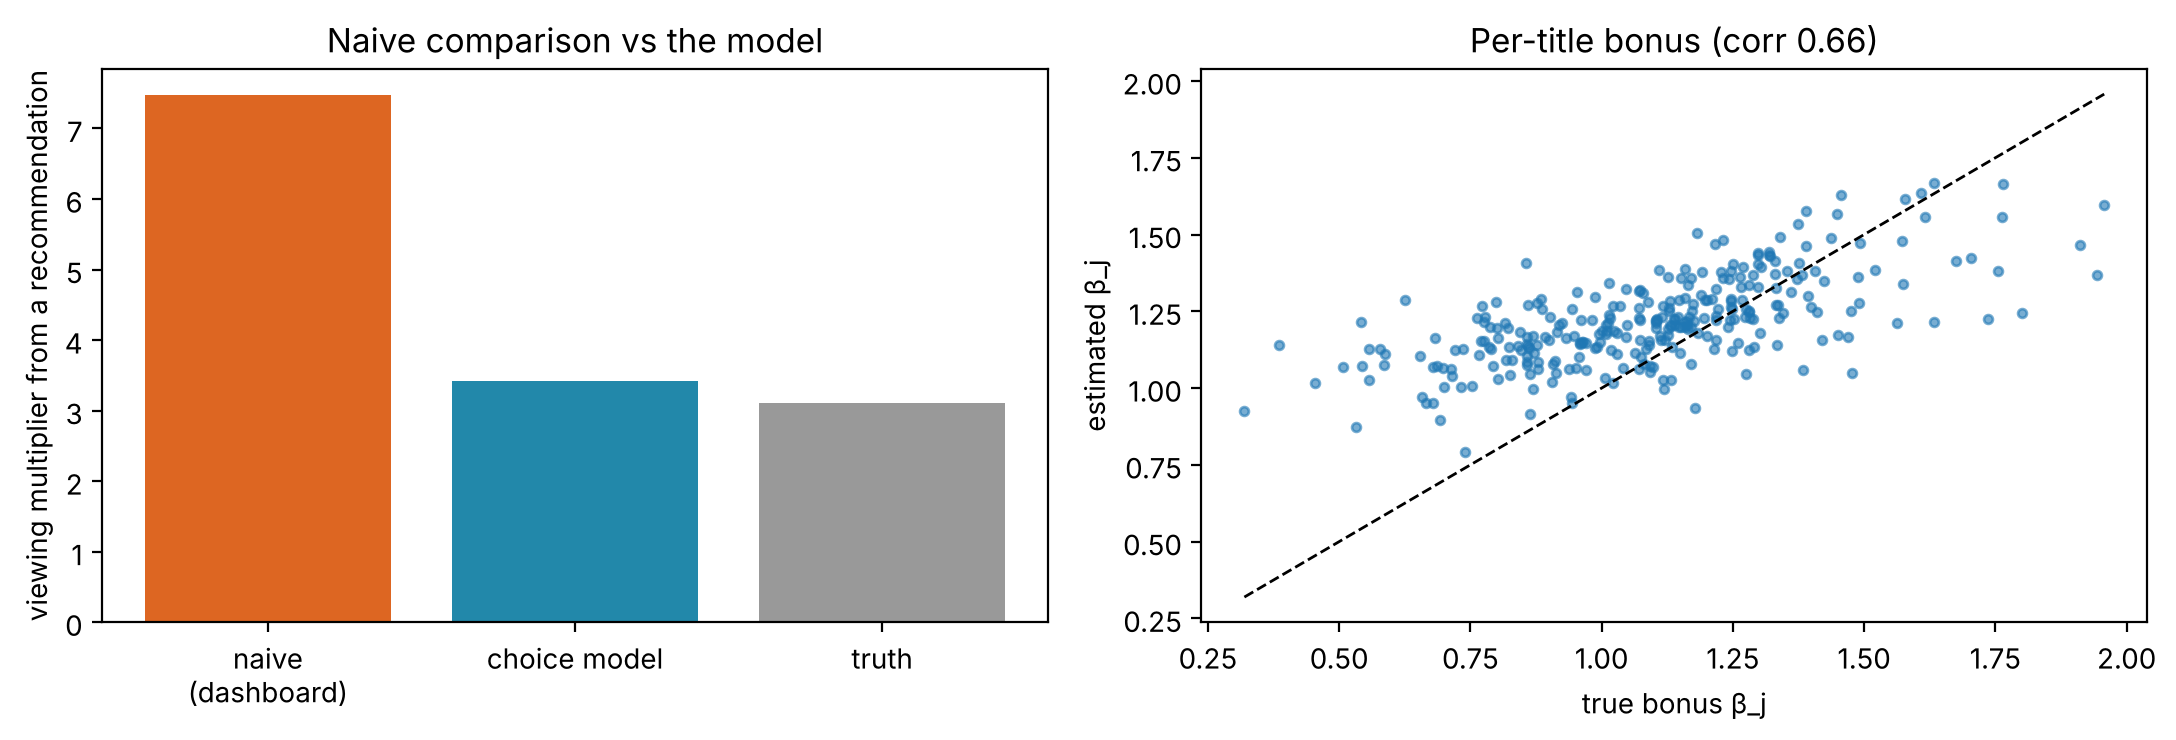

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(["naive\n(dashboard)", "choice model", "truth"],
            [naive_ratio, np.exp(BETA_HAT).mean(), true_ratio], color=["#d62", "#28a", "#999"])
axes[0].set_ylabel("viewing multiplier from a recommendation")
axes[0].set_title("Naive comparison vs the model")
axes[1].scatter(BETA_TRUE, BETA_HAT, s=10, alpha=0.6)
lim = [min(BETA_TRUE.min(), BETA_HAT.min()), max(BETA_TRUE.max(), BETA_HAT.max())]
axes[1].plot(lim, lim, "k--", lw=1)
axes[1].set_xlabel("true bonus β_j"); axes[1].set_ylabel("estimated β_j")
axes[1].set_title(f"Per-title bonus (corr {np.corrcoef(BETA_TRUE, BETA_HAT)[0,1]:.2f})")
plt.tight_layout(); plt.savefig("figures/fig1_naive_vs_model.png", dpi=130); plt.show()

**Is the leftover gap the estimator's fault, or the taste model's?** Plain check: give the same likelihood the *true* taste (`v_ij` from Assumption 1) as a fixed input and fit only the bonuses. If it lands near 1.10, the estimator is fine and the gap comes from how well we rebuild taste from history.

In [7]:
V_T = torch.tensor(V_TRUE, dtype=torch.float32)
beta_o = nn.Parameter(torch.zeros(J)); opt = torch.optim.Adam([beta_o], lr=0.05)
hist_b, wd_t, recs_t, ch_t = torch.tensor(HIST), torch.tensor(WATCH_DAY), torch.tensor(RECS), torch.tensor(CHOICE)
mi = np.repeat(np.arange(I), T_DAYS); ti = np.tile(np.arange(T_DAYS), I)
for ep in range(8):
    perm = np.random.default_rng(ep).permutation(len(mi))
    for k in range(0, len(mi), 4096):
        b = perm[k:k + 4096]; m_ = torch.tensor(mi[b]); t_ = torch.tensor(ti[b])
        u = V_T[m_] + beta_o * torch.zeros(len(b), J).scatter_(1, recs_t[m_, t_], 1.0)
        u = u.masked_fill(hist_b[m_] | (wd_t[m_] < t_[:, None]), -1e9)
        loss = nn.functional.cross_entropy(torch.cat([u, torch.zeros(len(b), 1)], 1), ch_t[m_, t_])
        opt.zero_grad(); loss.backward(); opt.step()
print(f"rec bonus with TRUE taste given: {beta_o.detach().numpy().mean():.3f}  (true {BETA_TRUE.mean():.3f}, our model {BETA_HAT.mean():.3f})")

rec bonus with TRUE taste given: 1.018  (true 1.096, our model 1.218)


## 5. Validation: does the model predict a real nudge experiment?

Netflix ran small A/B tests that push recommendations away from a set of titles, then measured **where the lost viewing went** — the *diversion ratio*:

`D(g→k) = [P_k(arm g) − P_k(control)] / −[P_g(arm g) − P_g(control)]`

In words: of the viewing that genre g lost, what share moved to group k (another genre, or "nothing")?

Plain steps:
1. Freeze everyone's state after day 40.
2. **Experiment** (model-free, with sampling noise): for each of 8 genres, an arm where that genre is never recommended. Simulate 5 days of real choices per arm.
3. **Prediction**: the fitted model's expected probabilities under the same arms.
4. Compare the two for every (genre, destination) pair.

In [8]:
GENRES = ["Drama", "Comedy", "Action", "Thriller", "Adventure", "Sci-Fi", "Romance", "Animation"]
gmask = {g: genres.apply(lambda x, g=g: g in x).values for g in GENRES}
REC_SCORE = V_TRUE + REC_NOISE

def arm_recs(rng, block=None):
    w = WATCHED_END.copy()
    if block is not None:
        w = w | gmask[block][None, :]          # recommender skips the blocked genre
    return gumbel_topk(REC_SCORE, w, rng)

def group_shares(p, p0, g_from):
    # share of viewing for: the blocked genre, each other genre (titles NOT in g_from), and "nothing"
    out = {"g": p[:, gmask[g_from]].sum(1).mean(), "nothing": p0.mean()}
    for k in GENRES:
        if k != g_from:
            out[k] = p[:, gmask[k] & ~gmask[g_from]].sum(1).mean()
    return out

def sampled_probs(rec, rng):
    # one simulated day of real choices -> empirical shares (model-free)
    p, p0 = choice_probs(V_TRUE, BETA_TRUE, rec, WATCHED_END)
    cum = np.hstack([p, p0[:, None]]).cumsum(1)
    ch = (rng.random((I, 1)) < cum).argmax(1)
    onehot = np.zeros((I, J + 1)); onehot[np.arange(I), ch] = 1
    return onehot[:, :J], onehot[:, J]

def diversion(shares_arm, shares_ctl):
    lost = -(shares_arm["g"] - shares_ctl["g"])
    return {k: (shares_arm[k] - shares_ctl[k]) / lost for k in shares_arm if k != "g"}

rows = []
REPS = 100                     # 100 simulated days per arm
for g in GENRES:
    exp_arm, exp_ctl, pred_arm, pred_ctl, true_arm, true_ctl = [], [], [], [], [], []
    for r in range(REPS):
        rr = np.random.default_rng(500 + r)
        rec_c, rec_a = arm_recs(rr), arm_recs(rr, g)
        exp_ctl.append(group_shares(*sampled_probs(rec_c, rr), g))
        exp_arm.append(group_shares(*sampled_probs(rec_a, rr), g))
        pred_ctl.append(group_shares(*choice_probs(V_HAT, BETA_HAT, rec_c, WATCHED_END), g))
        pred_arm.append(group_shares(*choice_probs(V_HAT, BETA_HAT, rec_a, WATCHED_END), g))
        true_ctl.append(group_shares(*choice_probs(V_TRUE, BETA_TRUE, rec_c, WATCHED_END), g))
        true_arm.append(group_shares(*choice_probs(V_TRUE, BETA_TRUE, rec_a, WATCHED_END), g))
    avg = lambda L: {k: np.mean([x[k] for x in L]) for k in L[0]}
    de, dp, dt = diversion(avg(exp_arm), avg(exp_ctl)), diversion(avg(pred_arm), avg(pred_ctl)), diversion(avg(true_arm), avg(true_ctl))
    for k in de:
        rows.append(dict(blocked=g, to=k, experiment=de[k], model=dp[k], truth=dt[k]))
div = pd.DataFrame(rows)
r_exp = np.corrcoef(div.experiment, div.model)[0, 1]
r_true = np.corrcoef(div.truth, div.model)[0, 1]
print(f"{len(div)} (genre, destination) pairs")
print(f"model vs experiment: corr {r_exp:.2f}, R² {r_exp**2:.2f}   (Netflix: 0.86, 0.73)")
print(f"model vs noise-free truth: corr {r_true:.2f}")
print("share of lost viewing that went to 'nothing' (experiment, avg over genres):",
      div[div.to == "nothing"].experiment.mean().round(2))

64 (genre, destination) pairs
model vs experiment: corr 0.77, R² 0.59   (Netflix: 0.86, 0.73)
model vs noise-free truth: corr 0.99
share of lost viewing that went to 'nothing' (experiment, avg over genres): 0.26


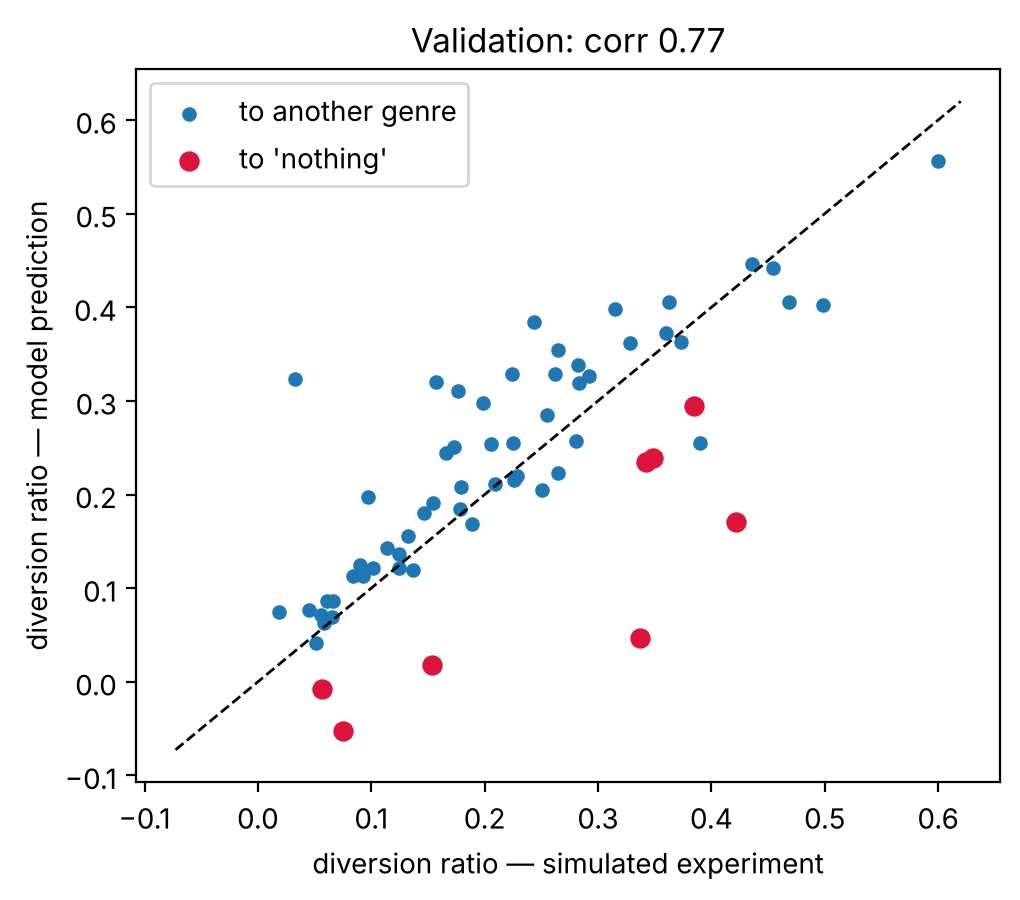

In [9]:
plt.figure(figsize=(5.2, 4.6))
isn = div.to == "nothing"
plt.scatter(div.experiment[~isn], div.model[~isn], s=18, label="to another genre")
plt.scatter(div.experiment[isn], div.model[isn], s=40, c="crimson", label="to 'nothing'")
lim = [min(div.experiment.min(), div.model.min()) - 0.02, max(div.experiment.max(), div.model.max()) + 0.02]
plt.plot(lim, lim, "k--", lw=1)
plt.xlabel("diversion ratio — simulated experiment"); plt.ylabel("diversion ratio — model prediction")
plt.title(f"Validation: corr {r_exp:.2f}")
plt.legend(); plt.tight_layout(); plt.savefig("figures/fig2_diversion.png", dpi=130); plt.show()

## 6. Counterfactuals: what if we swapped the recommender? (with uncertainty bands)

Plain steps, holding members and catalog fixed (state frozen after day 40), 10 slots each:
- **current**: the existing recommender (Assumption 5).
- **random**: 10 unwatched titles at random.
- **popularity**: the 10 most-popular unwatched titles.
- **matrix factorization**: vanilla SVD (rank 8) on the 40 days of viewing logs, top 10 unwatched. Untuned, like the paper's baseline.

Engagement = probability a member watches *something* today (= 1 − P(nothing)), the paper's Eq. 2. **Diversity** = share of viewing that goes to the 30 most popular titles (higher = more concentrated).

**The add-on:** the post gives point estimates only. We refit the model on 10 bootstrap resamples of members and report a 90% interval. And because it's a simulation, we also print the **true** answer.

In [10]:
# MF baseline: SVD on in-period viewing only
VIEW = csr_matrix(((CHOICE < J)[CHOICE < J].astype(float),
                   (np.nonzero(CHOICE < J)[0], CHOICE[CHOICE < J])), shape=(I, J))
mu_, ms_, mvt_ = svds(VIEW.astype(float), k=8)
MF_SCORE = (mu_ * ms_) @ mvt_

def topk_unwatched(score, k=N_SLOTS):
    s = np.where(WATCHED_END, -np.inf, score)
    return np.argpartition(-s, k, axis=1)[:, :k]

def policy_recs(name, rng):
    if name == "current": return arm_recs(rng)
    if name == "random": return gumbel_topk(np.zeros((I, J)), WATCHED_END, rng, temp=1.0)
    if name == "popularity": return topk_unwatched(np.tile(pop, (I, 1)))
    if name == "matrix factorization": return topk_unwatched(MF_SCORE)

POLICIES = ["current", "random", "popularity", "matrix factorization"]
TOP30 = np.argsort(-pop)[:30]

def evaluate(v_base, beta, reps=5):
    out = {}
    for name in POLICIES:
        eng, conc = [], []
        for r in range(reps):
            rec = policy_recs(name, np.random.default_rng(700 + r))
            p, p0 = choice_probs(v_base, beta, rec, WATCHED_END)
            eng.append(1 - p0.mean()); conc.append(p[:, TOP30].sum() / p.sum())
        out[name] = (np.mean(eng), np.mean(conc))
    base = out["current"][0]
    return pd.DataFrame({n: {"engagement": e, "change vs current": e / base - 1, "top-30 share": c}
                         for n, (e, c) in out.items()}).T

truth_cf = evaluate(V_TRUE, BETA_TRUE)
model_cf = evaluate(V_HAT, BETA_HAT)

# bootstrap: resample members, refit, re-predict
boot = []
t0 = time.time()
for b in range(10):
    idx = np.random.default_rng(900 + b).choice(I, I, replace=True)
    mb = fit_choice_model(RECS, CHOICE, WATCH_DAY, members_idx=idx, seed=b)
    with torch.no_grad():
        vb = mb.base_util(torch.tensor(HIST, dtype=torch.float32)).numpy(); bb = mb.beta.numpy()
    boot.append(evaluate(vb, bb)["change vs current"])
boot = pd.DataFrame(boot)
print(f"bootstrap: 10 refits in {time.time()-t0:.0f}s")

cf = pd.DataFrame({"truth": truth_cf["change vs current"],
                   "model": model_cf["change vs current"],
                   "model 5%": boot.quantile(0.05), "model 95%": boot.quantile(0.95),
                   "top-30 share (truth)": truth_cf["top-30 share"]})
(cf * 100).round(1)

bootstrap: 10 refits in 170s


,truth,model,model 5%,model 95%,top-30 share (truth)
current,0.0,0.0,0.0,0.0,18.0
random,-6.0,-5.3,-5.4,-5.1,16.4
popularity,-0.4,0.8,0.1,1.6,28.0
matrix factorization,1.7,3.2,3.3,4.1,20.1


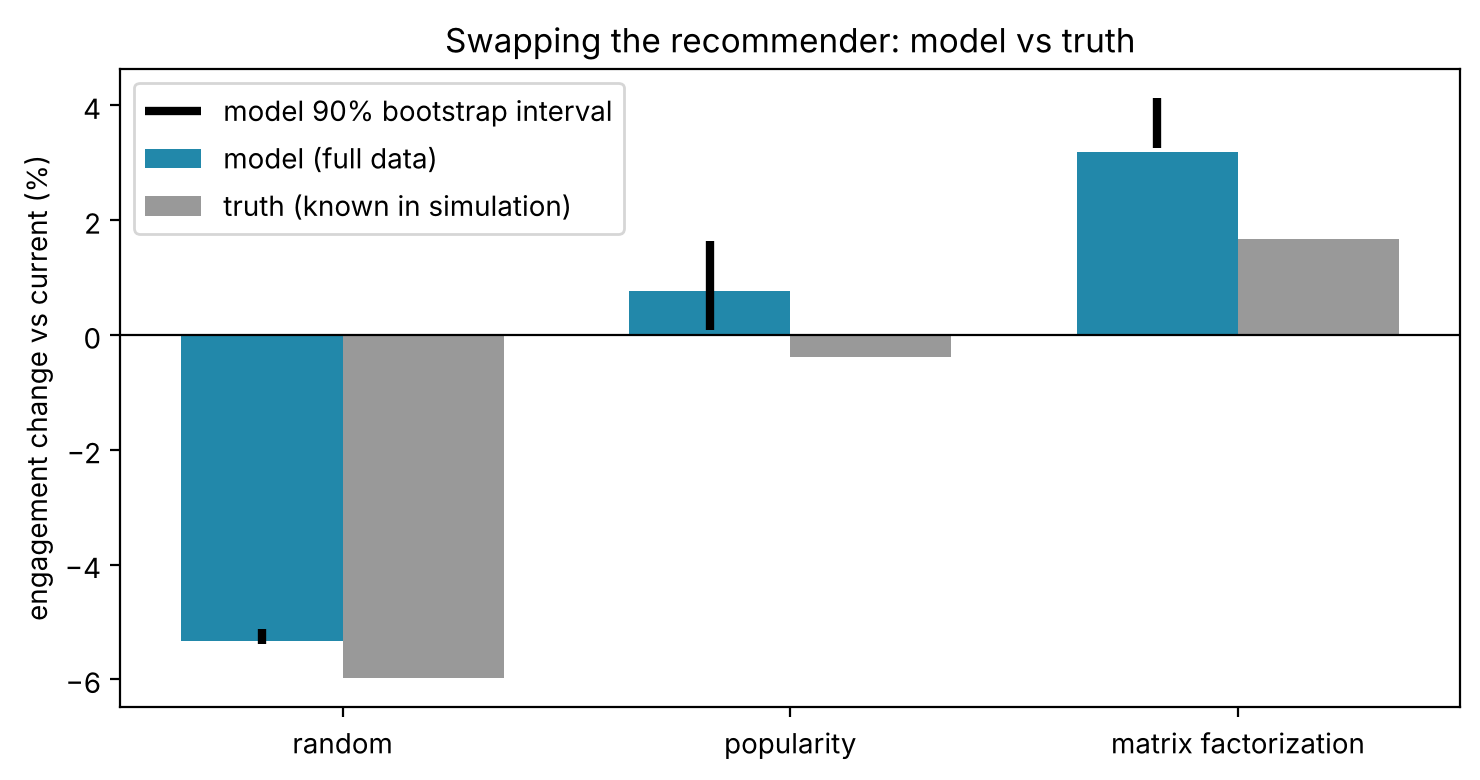

In [11]:
pol = POLICIES[1:]
x = np.arange(len(pol))
plt.figure(figsize=(7.5, 4))
m = cf.loc[pol, "model"] * 100
plt.bar(x - 0.18, m, 0.36, label="model (full data)", color="#28a")
# 90% bootstrap interval drawn as a black line (it need not contain the full-data estimate)
plt.vlines(x - 0.18, cf.loc[pol, "model 5%"] * 100, cf.loc[pol, "model 95%"] * 100,
           color="k", lw=3, label="model 90% bootstrap interval")
plt.bar(x + 0.18, cf.loc[pol, "truth"] * 100, 0.36, label="truth (known in simulation)", color="#999")
plt.axhline(0, color="k", lw=0.8)
plt.xticks(x, pol); plt.ylabel("engagement change vs current (%)")
plt.title("Swapping the recommender: model vs truth")
plt.legend(); plt.tight_layout(); plt.savefig("figures/fig3_counterfactuals.png", dpi=130); plt.show()

## 7. Decomposition: selection, exposure, targeting (the paper's Eq. 5)

For each title j, compare members who were **targeted** (j in their 10 recommendations) vs **everyone**:

- `Ȳ_j(1)`, `Ȳ_j(0)`: average watch probability over all members, with / without j recommended.
- `Ȳᵀ_j(1)`, `Ȳᵀ_j(0)`: same, only over targeted members.

Then: **selection** = `Ȳᵀ(0) − Ȳ(0)` (targeted people would have watched more anyway — not caused by the rec), **exposure** = `Ȳ(1) − Ȳ(0)` (effect of showing it to an average member), **targeting** = `[Ȳᵀ(1) − Ȳᵀ(0)] − [Ȳ(1) − Ȳ(0)]` (extra effect from showing it to the *right* people).

Plain operation for "with / without j": swap j into (or out of) one slot of today's 10 and recompute the logit. We average over which slot gets swapped, like the paper.

In [12]:
def decompose(v_base, beta, rec):
    Cm = np.zeros((I, J), bool); np.put_along_axis(Cm, rec, True, axis=1)
    u0 = np.where(WATCHED_END, -np.inf, v_base)
    e0 = np.exp(u0); e1 = np.exp(u0 + beta)                  # title j not shown / shown
    Z = np.where(Cm, e1, e0).sum(1) + 1.0                     # +1 = "nothing"
    # with j shown: if j not already shown, swap j into each slot r, average over r
    slot_delta = np.take_along_axis(e0, rec, 1) - np.take_along_axis(e1, rec, 1)   # (I, N)
    Z_in = Z[:, None, None] + slot_delta[:, None, :] + (e1 - e0)[:, :, None]       # (I, J, N)
    Y1 = np.where(Cm, e1 / Z[:, None], (e1[:, :, None] / Z_in).mean(2))
    # without j: if j shown, swap it out for an average unshown, unwatched title
    unshown = ~Cm & ~WATCHED_END
    avg_gain = ((e1 - e0) * unshown).sum(1) / unshown.sum(1)
    Z_out = Z[:, None] - e1 + e0 + avg_gain[:, None]
    Y0 = np.where(Cm, e0 / Z_out, e0 / Z[:, None])
    valid = ~WATCHED_END
    nT = (Cm & valid).sum(0)
    Ybar1 = (Y1 * valid).sum(0) / valid.sum(0); Ybar0 = (Y0 * valid).sum(0) / valid.sum(0)
    YT1 = (Y1 * Cm).sum(0) / np.maximum(nT, 1); YT0 = (Y0 * Cm).sum(0) / np.maximum(nT, 1)
    res = pd.DataFrame({"selection": YT0 - Ybar0, "exposure": Ybar1 - Ybar0,
                        "targeting": (YT1 - YT0) - (Ybar1 - Ybar0), "n_targeted": nT, "pop": pop})
    return res[res.n_targeted >= 20]                           # skip titles almost never shown

rec_today = arm_recs(np.random.default_rng(11))
dec_model = decompose(V_HAT, BETA_HAT, rec_today)
dec_true = decompose(V_TRUE, BETA_TRUE, rec_today)

def shares(dec):
    w = dec.n_targeted
    tot = (w * (dec.selection + dec.exposure + dec.targeting)).sum()
    return {k: (w * dec[k]).sum() / tot for k in ["selection", "exposure", "targeting"]}
sh = pd.DataFrame({"model": shares(dec_model), "truth": shares(dec_true),
                   "Netflix paper": {"selection": 0.513, "exposure": 0.068, "targeting": 0.419}})
(sh * 100).round(1)

,model,truth,Netflix paper
selection,11.8,17.0,51.3
exposure,59.1,48.0,6.8
targeting,29.0,35.0,41.9


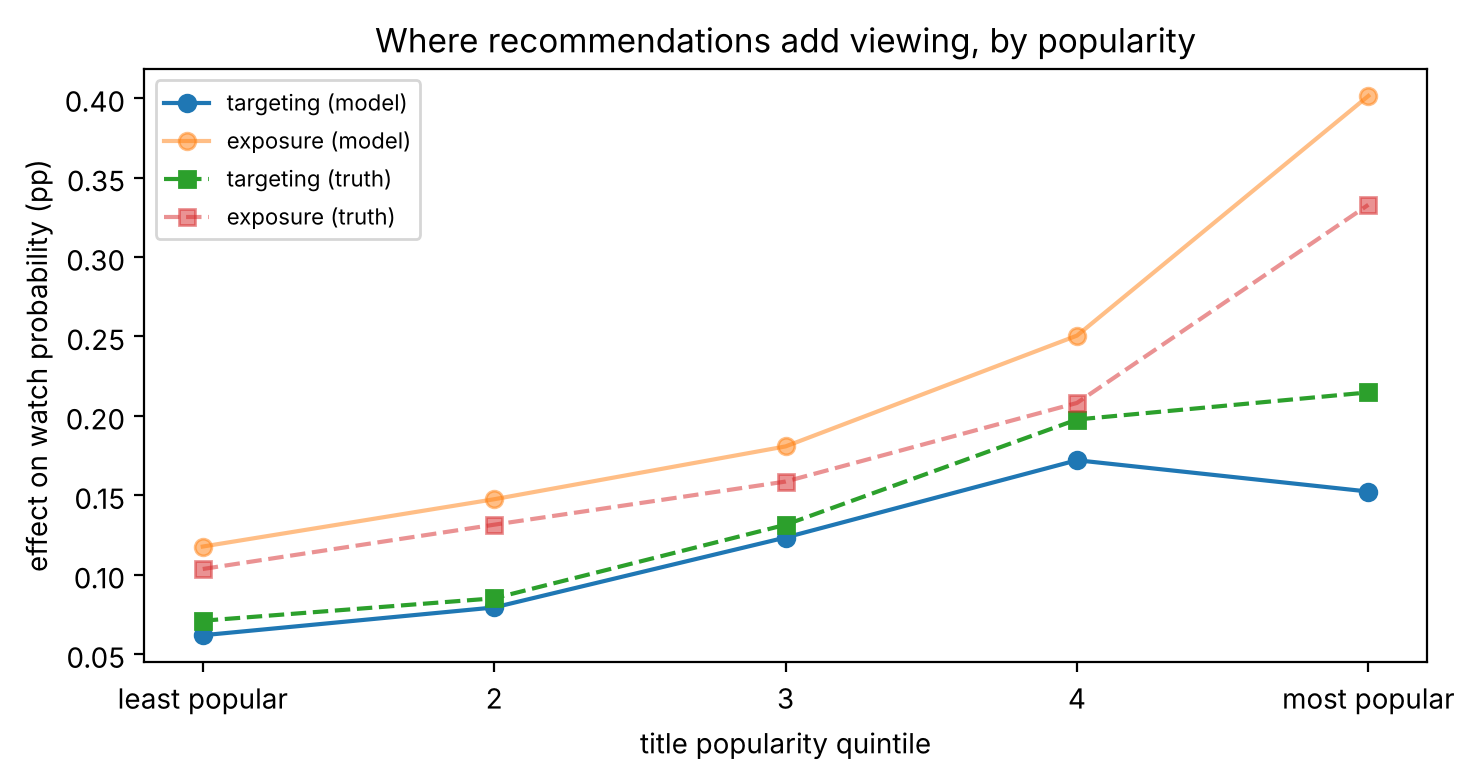

In [13]:
bins = pd.qcut(dec_model["pop"], 5, labels=["least popular", "2", "3", "4", "most popular"])
fig, ax = plt.subplots(figsize=(7.5, 4))
for src, dec, mk in [("model", dec_model, "o-"), ("truth", dec_true, "s--")]:
    g = dec.groupby(bins, observed=True)[["exposure", "targeting"]].mean()
    ax.plot(g.index.astype(str), g.targeting * 100, mk, label=f"targeting ({src})")
    ax.plot(g.index.astype(str), g.exposure * 100, mk, alpha=0.5, label=f"exposure ({src})")
ax.set_ylabel("effect on watch probability (pp)"); ax.set_xlabel("title popularity quintile")
ax.set_title("Where recommendations add viewing, by popularity")
ax.legend(fontsize=8); plt.tight_layout(); plt.savefig("figures/fig4_decomposition.png", dpi=130); plt.show()

## 8. Stress test: what if the identification assumption is false?

Everything above relies on: *given what the model can see, which titles got recommended is random.* In real life, a recommender often uses signals the analyst's model doesn't have — a recent search, a trailer just watched, time of day.

Plain setup: add a hidden, persistent member-title "interest" `ξ_ij ~ Normal(0, 0.8)`. It raises true utility **and** the recommender sees it. The choice model does not (it isn't in the history). Everything else identical: re-simulate, refit, compare to truth.

In [14]:
XI = np.random.default_rng(77).normal(0, 0.8, (I, J))
V_TRUE2 = V_TRUE + XI
RECS2, CHOICE2, WD2, WEND2 = simulate(V_TRUE2, V_TRUE2 + REC_NOISE, np.random.default_rng(78))
model2 = fit_choice_model(RECS2, CHOICE2, WD2, seed=5)
with torch.no_grad():
    BETA_HAT2 = model2.beta.numpy()
print(f"rec bonus — true {BETA_TRUE.mean():.2f} | model, assumption holds {BETA_HAT.mean():.2f} | model, assumption broken {BETA_HAT2.mean():.2f}")
print(f"multiplier — true {np.exp(BETA_TRUE).mean():.2f}x | broken-assumption model {np.exp(BETA_HAT2).mean():.2f}x")

rec bonus — true 1.10 | model, assumption holds 1.22 | model, assumption broken 1.94
multiplier — true 3.11x | broken-assumption model 7.04x


## 9. What this rebuild shows, and what it can't

**Shows (verified end to end, numbers above):**
1. **The dashboard number is wrong by 2.4×.** Naive "recommended vs not" says recommendations multiply viewing by **7.5×**. The truth is **3.1×**. The choice model says **3.4×**.
2. **The model's leftover gap (bonus +11%, multiplier +10%) comes from the taste model, not the estimator.** Given the true tastes, the same likelihood recovers the bonus (1.02 vs 1.10). Our history-based taste model can't fully rebuild what the recommender knew, so a bit of selection leaks into the bonus. A plain mean-pooling encoder (no normalization) was worse: bonus +24%. Better member models mean less bias. Training longer didn't help.
3. **Validation works, if the experiment is big enough.** Predicted vs simulated-experiment diversion ratios: correlation **0.77** (100 days × 4,000 members per arm; Netflix: 0.86). Against the noise-free truth: **0.99**. The gap is experiment noise, not the model. About a quarter of the viewing a genre lost went to "nothing" — the rest moved to other titles.
4. **The bootstrap intervals were too narrow: all three missed the truth.** The model gets the ranking right (random is worst, matrix factorization best) but popularity flips sign (+0.8% predicted vs −0.4% true). Bootstrap only captures sampling noise. It says nothing about model bias. Netflix reports no intervals; adding bootstrap ones would look rigorous and still mislead.
5. **The decomposition depends on the world.** Here exposure is the biggest share (truth 48%), not selection (Netflix 51%). Our recommender explores a lot and our catalog is the 300 most popular titles, so there's less "would have watched anyway". Targeting grows with popularity here; Netflix found it peaks mid-popularity. With no truly niche titles in our catalog, we can't see the downturn.
6. **Break the assumption and the model is as wrong as the dashboard.** With one hidden signal the recommender uses and the model can't see, the estimated multiplier goes to **7.0×** (truth 3.1×). The fancy model then gives you the naive answer with more confidence.

**Takeaway for anyone doing this at work:** the method is right, but its answer is only as good as (a) how much of the recommender's information your model sees, and (b) honest uncertainty. Check the first with a nudge experiment like Netflix did. For the second, don't stop at a bootstrap.

**Can't show:** real effect sizes. Viewing is simulated (Assumptions 1–5). The paper's model also has state dependence over the viewing sequence and several page canvases; ours has one canvas and a no-rewatch rule.

Source: [Measuring the Impact of Personalized Recommendations](https://netflixtechblog.com/measuring-the-impact-of-personalized-recommendations-4c26be3a4d96), paper [arXiv 2511.07280](https://arxiv.org/abs/2511.07280). Code: [github.com/ZFayFay/netflix-rec-impact-replication](https://github.com/ZFayFay/netflix-rec-impact-replication)